# Colour scan → LAS (pyLogDigitizer 0.3.0)

This notebook walks a **colour raster well log** through the 0.3.0 colour-scan path:

1. Load the colour TIFF (or a raster PDF page).
2. Suggest an ink palette in CIELAB, then classify every pixel.
3. Find the tracks, the depth column and the depth numbers automatically (no hand-given track positions).
4. Read the curve header (names and scales).
5. Build one black-on-white working image per curve and trace it with the colour-scan preset.
6. Compare against the matching public LAS.

The example is a small public crop of the Kansas Geological Survey copy of the BEREXCO STONE #5-19 triple combo (Eli Wireline, 2024), with the matching LAS over the same depth window. Provenance, credit line and terms are in `example_data/SOURCES.txt`.

**What this file is.** A *colour raster*: an RGB TIFF made of pixels only, written by the logging company's plotting software. It has no vector paths and no embedded curve values, so recovering the curves from the coloured ink and comparing them with the separate LAS is a true tracing test. Because the sheet is a clean digital plot (not a paper scan), the agreement is an upper bound for what a stained paper scan would give.

## 1. The example and its provenance

- Well: BEREXCO, LLC. STONE #5-19, API 15-055-22611, Ivanhoe Extension field, Finney County, Kansas.
- Log: Eli Wireline triple combo (induction, neutron-density, PE), logged 2 Aug 2024.
- Well page: https://chasm.kgs.ku.edu/ords/qualified.well_page.DisplayWell?f_kid=1054891848
- Credit: *The source of this material is the Kansas Geological Survey website at http://www.kgs.ku.edu/. All Rights Reserved.* (KGS terms allow reuse and redistribution with this credit; provided as-is.)

The shipped crop (`triple_combo_color_crop.tif`, about 500 KB, exact indexed colour) joins the printed curve-header band with a body window covering about 4390–4890 ft (10 px/ft). The slim LAS (`STONE_5-19_triple_combo_4385-4895.las`) is the separate KCC/KGS digital file cut to the same window and the plotted curves.

The grid and the thin (3 px) track borders on this print are **mid-grey**. With the default ink threshold the grey disappears and no track layout can be found, so `analyze_layout` retries with grey counted as ink and thin borders accepted; `L.layout_mode` records which pass worked.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from pylogdigitizer.scan_io import load_rgb, is_color_scan, read_info
from pylogdigitizer.scan_color import (
    COLOR_TRACE_PRESET, classify_colors, suggest_palette, is_color_rgb,
    plot_color_autodetect, plot_color_trace_pairs,
)
from pylogdigitizer.curve_ink import make_base_ink, make_curve_ink, save_ink_tif
from pylogdigitizer.header_ocr import propose_header
from pylogdigitizer.workflows import (
    analyze_layout, calibrate_depth, open_color_curve, color_curve_values,
)
from pylogdigitizer.las_export import read_las, resample, common_grid, write_las

ROOT = Path(".").resolve()
if not (ROOT / "example_data").exists():
    ROOT = ROOT.parent
WELL = ROOT / "example_data/STONE_5-19_15-055-22611"
SCAN = WELL / "triple_combo_color_crop.tif"
LAS = WELL / "STONE_5-19_triple_combo_4385-4895.las"
DETECT = ROOT / "image" / "ex_color_stone_detect.png"
PAIRS = ROOT / "image" / "ex_color_stone_trace.png"
print("scan exists:", SCAN.exists(), "LAS exists:", LAS.exists())
print(read_info(SCAN))
print("colour scan?", is_color_scan(SCAN))
STEP = 0.5   # LAS depth step in ft (default 0.5); any value greater than 0 works


scan exists: True LAS exists: True
{'width': 1600, 'height': 5414, 'mode': 'P', 'dpi': (200.0, 200.0)}
colour scan? True


**Input check:** `detect_input_kind` says what kind of file this is (image scan, vector PDF or mixed) and which method to use. Image files are always scans, so this notebook uses the image (tracing) workflow; vector PDFs are covered in notebook 06.


In [2]:
from pylogdigitizer import detect_input_kind
k = detect_input_kind(SCAN)
print(k.kind, "->", k.method_label)
print(k.evidence)


scan -> image workflow: clean-up, ink mask and curve tracing
{'format': 'TIFF', 'size_px': [1600, 5414], 'mode': 'P', 'n_frames': 1}


## 2. Why cluster in CIELAB?

A colour log prints each curve in its own ink. On stained or scanned paper the same ink can vary in brightness, so grouping pixels by raw RGB tends to split one pen into several “colours” or confuse it with the paper tint.

We convert to **CIELAB** (CIE 15, *Colorimetry*; see also Fairchild, *Color Appearance Models*, 2013) and run k-means there (MacQueen 1967; OpenCV’s implementation). Near-white, low-chroma pixels are ignored as paper; near-black ink is kept as `black`; centres closer than a Lab distance of 18 are merged as the same pen. The result is a suggested palette that the caller confirms or edits — a manual palette can still be passed straight to `classify_colors` / `prepare_color_scan`.

RGB (5414, 1600, 3) chromatic? True


suggested palette:
  white      RGB(255, 255, 255)
  black      RGB(0, 0, 0)
  gray       RGB(127, 127, 129)
  blue       RGB(0, 8, 252)
  red        RGB(245, 28, 2)
  green      RGB(7, 255, 3)
  green_2    RGB(0, 127, 2)
  yellow     RGB(235, 231, 191)


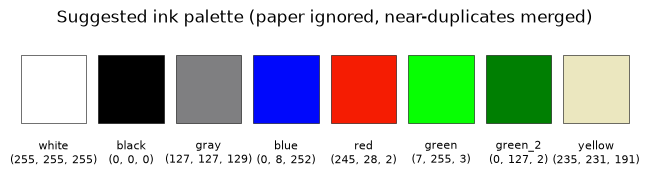

In [3]:
rgb = load_rgb(SCAN)
print("RGB", rgb.shape, "chromatic?", is_color_rgb(rgb))
palette = suggest_palette(rgb)
print("suggested palette:")
for name, col in palette.items():
    print(f"  {name:10s} RGB{col}")

fig, ax = plt.subplots(figsize=(8, 1.6))
ax.set_xlim(0, len(palette)); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("Suggested ink palette (paper ignored, near-duplicates merged)")
for i, (name, col) in enumerate(palette.items()):
    ax.add_patch(plt.Rectangle((i + 0.08, 0.25), 0.84, 0.55, color=np.array(col) / 255, ec="k", lw=0.4))
    ax.text(i + 0.5, 0.12, f"{name}\n{col}", ha="center", va="top", fontsize=8)
plt.show()

## 3. Classify the sheet

Every pixel is labelled with its nearest palette colour (RGB Euclidean distance, with a ceiling so unmatched stain counts as paper). That labelled sheet is what later steps use to build per-curve working images.

In [4]:
labels, names = classify_colors(rgb, palette)
print("classes:", names)
for n in names:
    print(f"  {n:10s} share={float((labels == names.index(n)).mean()):.5f}")

classes: ['white', 'black', 'gray', 'blue', 'red', 'green', 'green_2', 'yellow']
  white      share=0.86223
  black      share=0.01508
  gray       share=0.09025
  blue       share=0.02218
  red        share=0.00689
  green      share=0.00145
  green_2    share=0.00147
  yellow     share=0.00046


## 4. Automatic layout and depth

`analyze_layout` finds the first stable track layout below the header, follows the track borders down the sheet and picks the depth labels in the depth column. Nothing about the track positions is passed in. Depth numbers are then read with RapidOCR and fitted to a linear depth map; the log body starts where the first followed block begins.

In [5]:
L = analyze_layout(SCAN)
print("layout pass:", L.layout_mode, "| tracks:", L.track_names, "| first layout row:", L.probe_row)
for t in L.tracks:
    print(f"  {t['kind']:6s} x {t['left']:4d}-{t['right']:4d}  ({t.get('detector')})")

dm, anc, residuals, dchecks = calibrate_depth(L, track="track1", use_ocr=True)
print({k: dchecks[k] for k in ("px_per_ft", "first_depth", "interval", "n_labels", "source", "loo_max_ft", "ocr_agree")})

def track_x(name):
    li, ri = L.edge_names.index(name + ".left"), L.edge_names.index(name + ".right")
    return float(np.median(L.edges[:, li])), float(np.median(L.edges[:, ri]))

tracks = {n: track_x(n) for n in L.track_names}
HEADER_H = 414                       # rows of the printed curve-header band on top of the crop
print("track x (px):", {k: tuple(round(v) for v in xy) for k, xy in tracks.items()})
print("depth at body start / end:", round(float(dm(HEADER_H)), 1), round(float(dm(rgb.shape[0] - 1)), 1))

layout pass: grey_thin_borders | tracks: ['track1', 'track2', 'track3'] | first layout row: 400
  track  x    3- 479  (detect_tracks_thin)
  depth  x  482- 639  (detect_tracks_thin)
  track  x  642-1118  (detect_tracks_thin)
  track  x 1121-1597  (detect_tracks_thin)


{'px_per_ft': 10.0, 'first_depth': 4400.0, 'interval': 50.0, 'n_labels': 10, 'source': 'ocr', 'loo_max_ft': 0.0, 'ocr_agree': 10}
track x (px): {'track1': (1, 480), 'track2': (640, 1119), 'track3': (1119, 1598)}
depth at body start / end: 4389.9 4889.8


## 5. Header: names and scales

`propose_header` (the default) reads each track's header block, fuzzy-matches curve names to CWLS mnemonics and reads the printed left/right scale numbers. `parse="lines"` is an explicit option for prints that read *name, then “left UNIT right”*, keeping printed names. On this Eli header the default parser gives every printed curve row its own proposal and scale: deep, medium and shallow resistivity (`ILD`, `ILM`, `SFL`, each 0.2–200 log) and CN and density porosity (`NPHI`, `DPHI`, each 30 to −10) are separate rows. The small density-correction curve (printed `RHOC`, matched to `DRHO`) on a half-width scale in track 3 gets its own row too, but its scale is not read, so it is left for review and not traced here. The line parser only returns a couple of rows without scales.

In [6]:
H = propose_header(str(SCAN), layout=L, labels=labels, label_names=names)
print(f"default proposals ({len(H['curves'])}):")
for c in H["curves"]:
    lo, hi = c['scale_left']['value'], c['scale_right']['value']
    print(f"  {c['track']:8s} {c['mnemonic']['value']:6s} {str(lo):>7} .. {str(hi):<7} {c['scale_type']['value']}")
H2 = propose_header(str(SCAN), layout=L, parse="lines", labels=labels, label_names=names)
print(f"\nline-parser rows ({len(H2.get('line_curves') or [])}):")
for c in H2.get("line_curves") or []:
    print(f"  {c['name']:10s} color={c['color']:8s} {c['left']} .. {c['right']}  {c['check']}")

default proposals (10):
  track1   GR         0.0 .. 150.0   linear
  track1   SP      -100.0 .. 100.0   linear
  track1   CALI       6.0 .. 16.0    linear
  track2   ILD        0.2 .. 200.0   log
  track2   ILM        0.2 .. 200.0   log
  track2   SFL        0.2 .. 200.0   log
  track3   NPHI      30.0 .. -10.0   linear
  track3   DPHI      30.0 .. -10.0   linear
  track3   PE         0.0 .. 20.0    linear
  track3   DRHO      None .. None    linear



line-parser rows (2):
  RHOC       color=black    None .. None  no scale read
  GCC025     color=black    None .. None  no scale read


## 6. One working image per curve

The tracer follows dark ink. Isolating one palette colour, closing dash gaps (morphological closing; Serra 1982) and thickening the stroke gives it a single continuous line that beats thin grid lines. The grey printed grid is kept (as black) in each working image so the session can re-find the tracks and depth numbers. The colour-scan preset uses `min_area=0` (the global `trace_track` default of 400 would delete dotted lines) together with `min_width=5`, `straight_len=0`, `grid_frac=1.01`, `center_weight=0.3`; those values are a preset, not a change to the defaults.

Each curve below takes its scale from the OCR'd header proposal of its track (`hdr`), and its colour from the confirmed palette.

In [7]:
print("colour-scan preset:", COLOR_TRACE_PRESET)
scale = {c["mnemonic"]["value"]: c for c in H["curves"]}

UNITS = {"GR": "GAPI", "SP": "mV", "RILD": "ohm-m", "RILM": "ohm-m", "RLL3": "ohm-m",
         "CNPOR": "pu", "DPOR": "pu", "PE": "b/e"}

def from_header(name, color, hdr):
    c = scale[hdr]
    return dict(name=name, color=color, track=c["track"], left=c["scale_left"]["value"],
                right=c["scale_right"]["value"], scale_type=c["scale_type"]["value"], backup=None,
                unit=UNITS[name])

CURVES = [
    from_header("GR",    "blue",    "GR"),
    from_header("SP",    "red",     "SP"),
    from_header("RILD",  "green_2", "ILD"),
    from_header("RILM",  "red",     "ILM"),
    from_header("RLL3",  "blue",    "SFL"),
    from_header("CNPOR", "red",     "NPHI"),
    from_header("DPOR",  "blue",    "DPHI"),
    from_header("PE",    "green",   "PE"),
]
base = make_base_ink(labels, names, (HEADER_H, rgb.shape[0]))
WORK = ROOT / "outputs" / "color_scan_stone"
WORK.mkdir(parents=True, exist_ok=True)
ink_paths = {}
for cv in CURVES:
    ink = make_curve_ink(base, labels, names, cv["color"], tracks[cv["track"]], (HEADER_H, rgb.shape[0]))
    ink_paths[cv["name"]] = save_ink_tif(ink, WORK / f"working_{cv['name']}.tif")
    print(f"{cv['name']:6s} {cv['color']:8s} {cv['track']}  {cv['left']:g}..{cv['right']:g} {cv['scale_type']}")

colour-scan preset: {'min_width': 5, 'straight_len': 0, 'grid_frac': 1.01, 'center_weight': 0.3, 'min_area': 0, 'line_frac': 0.9}
GR     blue     track1  0..150 linear
SP     red      track1  -100..100 linear
RILD   green_2  track2  0.2..200 log
RILM   red      track2  0.2..200 log


RLL3   blue     track2  0.2..200 log
CNPOR  red      track3  30..-10 linear
DPOR   blue     track3  30..-10 linear
PE     green    track3  0..20 linear


## 7. Trace (dense connected points, no smoothing)

Each working image is opened as an assisted session (the session re-runs the automatic layout and depth calibration on the 1-bit image) and auto-traced. Values go onto a regular LAS grid by linear interpolation along the traced polyline only — no smoothing (`las_export.resample`, 0.5 ft here).

**Off-scale.** Where a curve runs past the track edge and its overflow re-enters from the other edge (a wrapped trace on those rows), the wrapped part is read on the backup scale (the printed one, or the next full track width when none is printed). Where the curve simply runs out at the edge and no wrapped trace exists on those rows (clipped), the depths are written as null.

In [8]:
sessions, series = {}, {}
for cv in CURVES:
    s = open_color_curve(ink_paths[cv["name"]], cv, "STONE_5-19", dict(COLOR_TRACE_PRESET),
                         x_range=tracks[cv["track"]], auto_backup=True)
    sessions[cv["name"]] = s
    d, v = color_curve_values(s)
    series[cv["name"]] = (d, v)
    print(f"{cv['name']:6s} layout={s.L.layout_mode:12s} n={len(d)} finite={int(np.isfinite(v).sum())} "
          f"{float(np.nanmin(d)):.0f}-{float(np.nanmax(d)):.0f} ft  backup={s.scale.get('backup')}  errors={s.errors}")

GR     layout=thin_borders n=2507 finite=2435 4389-4890 ft  backup=None  errors={}


SP     layout=thin_borders n=2507 finite=2507 4389-4890 ft  backup=None  errors={}


RILD   layout=thin_borders n=2507 finite=2507 4389-4890 ft  backup=None  errors={}


RILM   layout=thin_borders n=2507 finite=2507 4389-4890 ft  backup=None  errors={}


RLL3   layout=thin_borders n=2507 finite=2363 4389-4890 ft  backup=None  errors={}


CNPOR  layout=thin_borders n=2507 finite=2454 4389-4890 ft  backup=None  errors={}


DPOR   layout=thin_borders n=2507 finite=2484 4389-4890 ft  backup=None  errors={}


PE     layout=thin_borders n=2507 finite=2507 4389-4890 ft  backup=None  errors={}


## 8. Compare with the public LAS

Pearson’s *r*, RMSE and bias after resampling the trace onto the LAS 0.5 ft grid (no smoothing). GR and the shallow resistivity RLL3 go off scale in a few beds. This print clips them at the track edge: no wrapped trace re-enters from the other edge, so those depths are written as null (see step 7) and are left out of the score. Each curve is also scored on the points where the LAS value is inside the printed scale. Short spikes past the edge (under about 2 ft) that the tracer cuts across below the edge keep a value and count against the score.

In [9]:
ref = read_las(LAS).df().sort_index()
print("LAS depth", float(ref.index.min()), "-", float(ref.index.max()), "curves", list(ref.columns))

def qc(depth, value, cv):
    g, v = resample(depth, value, STEP)
    rv = np.asarray(ref[cv["name"]], float); rd = np.asarray(ref.index, float)
    ok = np.isfinite(rv)
    ri = np.interp(g, rd[ok], rv[ok], left=np.nan, right=np.nan)
    m = np.isfinite(v) & np.isfinite(ri)
    lo, hi = sorted((cv["left"], cv["right"]))
    ins = m & (ri >= lo) & (ri <= hi)
    st = lambda k: (float(np.corrcoef(v[k], ri[k])[0, 1]), float(np.sqrt(np.mean((v[k] - ri[k]) ** 2))),
                    float(np.mean(v[k] - ri[k])), int(k.sum()))
    return st(m), st(ins)

QC = {}
print(f"{'curve':6s} {'r':>7s} {'RMSE':>7s} {'bias':>7s} {'n':>5s} | in-scale r  RMSE    n | LAS off-scale  null")
for cv in CURVES:
    a, b = qc(*series[cv["name"]], cv)
    QC[cv["name"]] = (a, b)
    g, v = resample(*series[cv["name"]], STEP)
    rv = np.interp(g, ref.index.values, np.asarray(ref[cv["name"]], float), left=np.nan, right=np.nan)
    lo, hi = sorted((cv["left"], cv["right"]))
    off = np.isfinite(rv) & ((rv < lo) | (rv > hi))
    print(f"{cv['name']:6s} {a[0]:7.4f} {a[1]:7.3f} {a[2]:+7.3f} {a[3]:5d} | {b[0]:8.4f} {b[1]:7.3f} {b[3]:5d} | {int(off.sum()):13d} {int((off & ~np.isfinite(v)).sum()):5d}")

LAS depth 4385.0 - 4895.0 curves ['GR', 'SP', 'RILD', 'RILM', 'RLL3', 'CNPOR', 'DPOR', 'PE', 'RHOC', 'DCAL']
curve        r    RMSE    bias     n | in-scale r  RMSE    n | LAS off-scale  null
GR      0.9846   4.963  -0.293   971 |   0.9909   3.439   964 |            26    19
SP      0.9996   0.500  -0.218  1003 |   0.9996   0.500  1003 |             0     0
RILD    0.9991   0.591  -0.201  1003 |   0.9991   0.591  1003 |             0     0
RILM    0.9995   0.634  -0.270  1003 |   0.9995   0.634  1003 |             0     0
RLL3    0.9196  23.895  -4.383   938 |   0.9651  11.795   918 |            58    38
CNPOR   0.9981   0.385  -0.007   981 |   0.9985   0.339   976 |            17    12
DPOR    0.9981   0.339  -0.005   993 |   0.9981   0.339   993 |             8     8
PE      0.9967   0.052  -0.011  1003 |   0.9967   0.052  1003 |             0     0


## 9. Figures (`image/ex_color_stone_detect.png`, `image/ex_color_stone_trace.png`)

Two compact figures over the same 100 ft window.

1. **Auto-detection** — what pyLogDigitizer identified: OCR'd header names and scales (annotated on each track), detected track borders and grid lines, and the traced curves in their print colours, next to the raw crop. Drawn by `scan_color.plot_color_autodetect`.
2. **Pre-traced vs traced** — for GR, RILD, CNPOR and DPOR, side by side: the curve's own isolated stroke from its working image, cropped to exactly its track, and the trace, on the same x extent (ticks in the printed scale and unit; log for RILD) and depth range, with a faint grid. Drawn by `scan_color.plot_color_trace_pairs`.

Agreement scores stay in the README table, not on the plots.

wrote image/ex_color_stone_detect.png 208129 bytes


wrote image/ex_color_stone_trace.png 140080 bytes


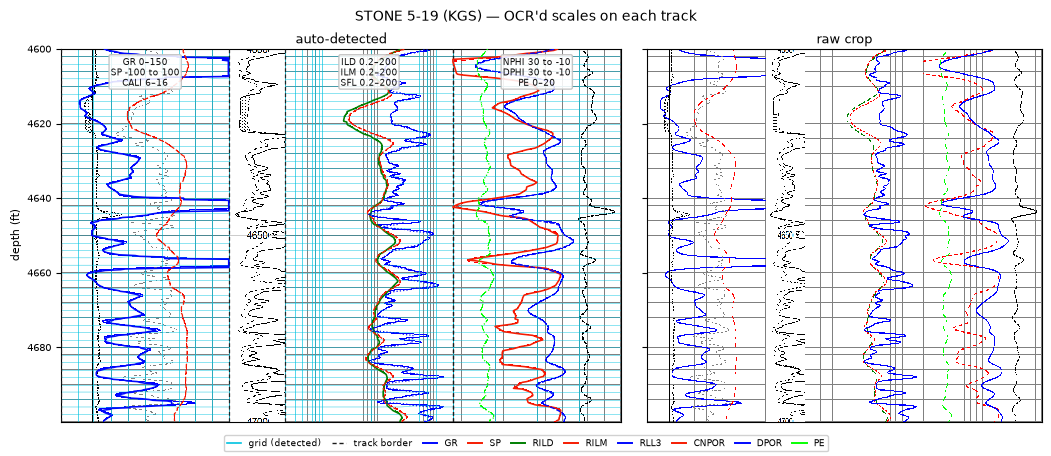

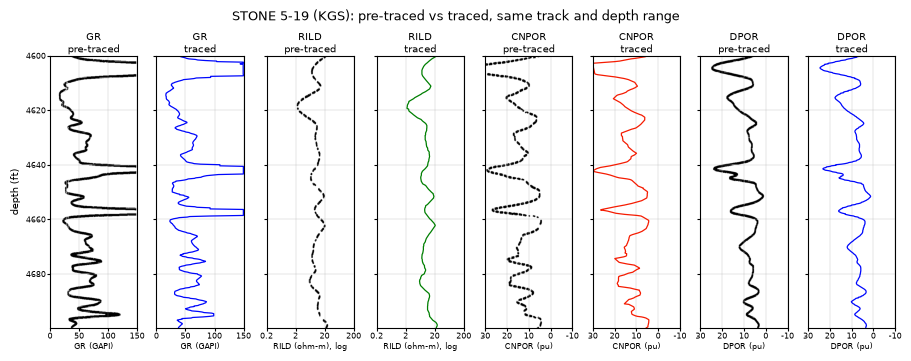

In [10]:
def sheet_trace(cv):
    R = sessions[cv["name"]].result()
    rows = np.asarray(R["rows"], float)
    xp = np.asarray(R["x_panel"], float)
    xl = np.interp(rows, L.centers, L.edges[:, L.edge_names.index(cv["track"] + ".left")])
    return np.asarray(R["depth"], float), xl + xp

traces = {cv["name"]: sheet_trace(cv) for cv in CURVES}
def scale_text(lo, hi):
    return f"{lo:g} to {hi:g}" if min(lo, hi) < 0 else f"{lo:g}–{hi:g}"

ocr_notes = [dict(track=c["track"], label=f"{c['mnemonic']['value']} {scale_text(c['scale_left']['value'], c['scale_right']['value'])}")
             for c in H["curves"] if c["scale_left"]["value"] is not None and c["scale_right"]["value"] is not None]
WINDOW = (4600, 4700)

DETECT.parent.mkdir(parents=True, exist_ok=True)
fig1 = plot_color_autodetect(rgb, dm, WINDOW, palette, CURVES, traces, tracks,
                             layout=L, ocr_notes=ocr_notes, title="STONE 5-19 (KGS) — OCR'd scales on each track")
fig1.savefig(DETECT, dpi=140, bbox_inches="tight")
print("wrote", DETECT.relative_to(ROOT), DETECT.stat().st_size, "bytes")

pair_curves = [cv for cv in CURVES if cv["name"] in ("GR", "RILD", "CNPOR", "DPOR")]
fig2 = plot_color_trace_pairs(ink_paths, traces, pair_curves, dm, WINDOW, tracks, palette,
                              base_ink=base, title="STONE 5-19 (KGS): pre-traced vs traced, same track and depth range")
fig2.savefig(PAIRS, dpi=140, bbox_inches="tight")
print("wrote", PAIRS.relative_to(ROOT), PAIRS.stat().st_size, "bytes")
plt.show()

## 10. Write LAS (0.5 ft grid, no smoothing)

`common_grid` puts every traced curve on one regular depth grid (0.5 ft here; 0.25 ft is the other allowed step).

In [11]:
grid, curves = common_grid(series, step=STEP)
units = {"GR": "GAPI", "SP": "MV", "RILD": "OHMM", "RILM": "OHMM", "RLL3": "OHMM",
         "CNPOR": "PU", "DPOR": "PU", "PE": "B/E"}
out = WORK / "STONE_5-19_color_scan.las"
write_las(out, grid, curves, units=units, well={"WELL": "STONE #5-19", "UWI": "15-055-22611"})
print("wrote", out.relative_to(ROOT), "n=", len(grid), "from", float(grid[0]), "to", float(grid[-1]))
for k, v in curves.items():
    print(f"  {k:6s} finite {int(np.isfinite(v).sum())}/{len(v)}")

wrote outputs/color_scan_stone/STONE_5-19_color_scan.las n= 1003 from 4389.0 to 4890.0
  GR     finite 971/1003
  SP     finite 1003/1003
  RILD   finite 1003/1003
  RILM   finite 1003/1003
  RLL3   finite 938/1003
  CNPOR  finite 981/1003
  DPOR   finite 993/1003
  PE     finite 1003/1003


## Notes

- The colour-scan tracer preset does not change `trace_track` defaults; black-and-white scans behave as before.
- Grey-grid digital plots (Eli, Gemini and similar) are found automatically: `layout_mode` is `grey_thin_borders` on the colour crop and `thin_borders` on the 1-bit working images.
- In the local browser app (`pylogdigitizer-app`) the same flow is five tabs: open the scan, check tracks and depth, pick each curve (its colour or line style is identified automatically; name, scale, unit and backup scale sit beside the viewer), trace and fix, check and save the LAS.
- Black-and-white scans use the same flow with line styles instead of colours: see `05_line_styles_to_las.ipynb`.